Matplotlib is building the font cache; this may take a moment.


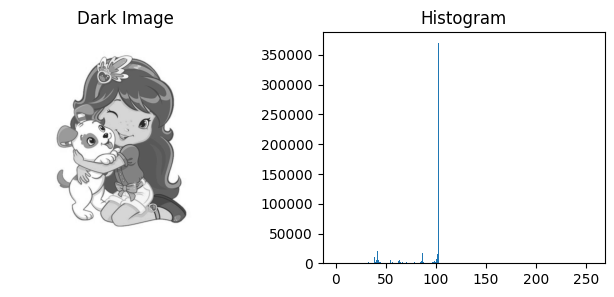

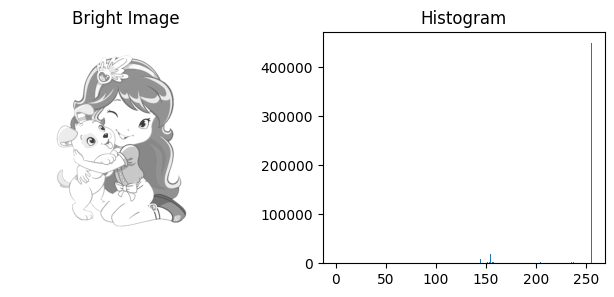

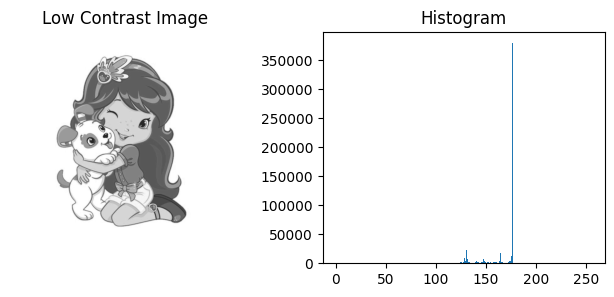

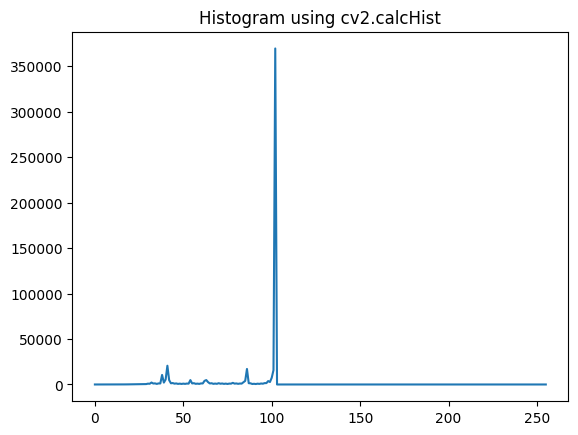

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
img = cv2.imread("task2.jpg", cv2.IMREAD_GRAYSCALE)
if img is None:
    print("Image not found!")
else:
    dark = (img * 0.4).astype(np.uint8)
    bright = np.clip(img * 1.5, 0, 255).astype(np.uint8)
    low_contrast = np.clip(img * 0.3 + 100, 0, 255).astype(np.uint8)

    images = [dark, bright, low_contrast]
    names = ["Dark Image", "Bright Image", "Low Contrast Image"]
    for i in range(3):
        plt.figure(figsize=(8, 3))

        plt.subplot(1, 2, 1)
        plt.imshow(images[i], cmap='gray')
        plt.title(names[i])
        plt.axis('off')

        plt.subplot(1, 2, 2)
        plt.hist(images[i].ravel(), bins=256, range=(0, 256))
        plt.title("Histogram")

        plt.show()
    hist = cv2.calcHist([dark], [0], None, [256], [0, 256])
    plt.plot(hist)
    plt.title("Histogram using cv2.calcHist")
    plt.show()

dark => most pixels concentrated on left side  bec the low intensity values
bright => most pixels concentrated on right side  bec the high intensity values
low contrast => pixels concentrated in a narrow range bec the small diffrence between pixels intensites


In [ ]:
import numpy as np

def my_equalize(img, L=8):

    N = img.size
    hist = np.zeros(L)

    for pixel in img.ravel():
        hist[pixel] += 1
    pdf = hist / N
    cdf = np.cumsum(pdf)
    sk = np.round((L - 1) * cdf).astype(int)

    output = sk[img]

    return output

img = np.array([
    [1, 1, 2, 2],
    [1, 2, 2, 3],
    [2, 3, 3, 6],
    [2, 3, 6, 7]
])
result = my_equalize(img, L=8)

print("Original Image:")
print(img)

print("Equalized Image:")
print(result)

Original Image:
[[1 1 2 2]
 [1 2 2 3]
 [2 3 3 6]
 [2 3 6 7]]
Equalized Image:
[[1 1 4 4]
 [1 4 4 6]
 [4 6 6 7]
 [4 6 7 7]]
